In [1]:
# conda vis2
from pathlib import Path
PROJECT_ROOT = Path().resolve().parent.parent.parent
EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V04' / 'default'
ITERATIONS = EXPERIMENT / 'iterations'
INTERIM_DATA = PROJECT_ROOT / 'data' / 'interim'
FIGURE_OUT = PROJECT_ROOT / 'figures'

import sys
sys.path.append(str(PROJECT_ROOT))

import glob
import plotly.graph_objects as go
import os
import numpy as np
import at3d
import matplotlib.pyplot as plt
import xarray as xr
from src.utils.util import load_sensor_dict
from scipy.interpolate import griddata

savefigs = True
fig_version = 'V03'

In [2]:
def set_labels(ax_flat):
    labels = ['a)', 'b)', 'c)', 'd)', 'e)', 'f)', 'g)', 'h)', 'i)']
    for i, a in enumerate(ax_flat):
        a.set_title(
            labels[i],
            fontfamily='serif',
            loc='left',
            fontsize='medium',
            fontweight='bold'
        )


In [3]:
iter_files = sorted(ITERATIONS.glob('iter*.nc'))
sensors, solvers, rte_grid = at3d.util.load_forward_model(iter_files[-1])
cloud = solvers[0.67].medium['cloud']

cvm_file = INTERIM_DATA / 'CVM_CAMP2Ex_RF17_default_open.nc'
cvm = xr.load_dataset(cvm_file)

obs_file = INTERIM_DATA / 'AT3D_OBS_CAMP2Ex_RF17_default.nc'
obs = load_sensor_dict(obs_file)

/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '51'. Max cell optical depth: '3.0740342140197754'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "


### Figure 8: 3D Extinction

In [4]:
vmin = 0
vmax = 37.5

X, Y, Z = np.meshgrid(cloud.x.data, cloud.y.data, cloud.z.data, indexing='ij')
data = go.Volume(
    x=X.flatten(),
    y=Y.flatten(),
    z=Z.flatten(),
    value=cloud.extinction.data.flatten(),
    isomin=vmin,
    isomax=vmax, 
    opacity=0.1,
    surface_count=17,
    showscale=True,
    colorbar=dict(
        title='Extinction',
        titleside='right',
        tickmode='array',
        tickvals=[vmin, 0.5*(vmin+vmax), vmax],
        ticktext=['Low', 'Medium', 'High'],
        len=0.8,
        thickness=20
    )
)
layout = go.Layout(autosize=False, width=750, height=650)
fig = go.Figure(data=data, layout=layout)
pad = {'b':0, 'l':0, 'r':0, 't':0, 'pad':0}
font = {'size':16}
scene = dict(
    xaxis=dict(title='x (km)', tickvals=[0, 4.4, 8.8, 13.2, 17.6], range=[-1, 18.6]),
    yaxis=dict(title='y (km)', tickvals=[0, 4.4, 8.8, 13.2, 17.6], range=[-1, 18.6]),
    zaxis=dict(title='z (km)', tickvals=[0, 1.4], range=[-0.1, 1.5]),
)

theta = np.radians(45)
phi = -0.3*np.pi
r = 2.5
h = r * np.sin(theta)

camera = dict(
    up=dict(x=0, y=0, z=1.0),
    center=dict(x=0.0, y=0.0, z=0.0),
    eye=dict(x=h*np.cos(phi), y=h*np.sin(phi), z=r*np.cos(theta))
)
fig.update_layout(
    scene_camera=camera,
    margin=pad,
    font=font,
    scene=scene
)
if(savefigs):
    fig.write_image(FIGURE_OUT / '{}_figure08_3D_extinction.png'.format(fig_version))

### Figure 9: extinction cross section

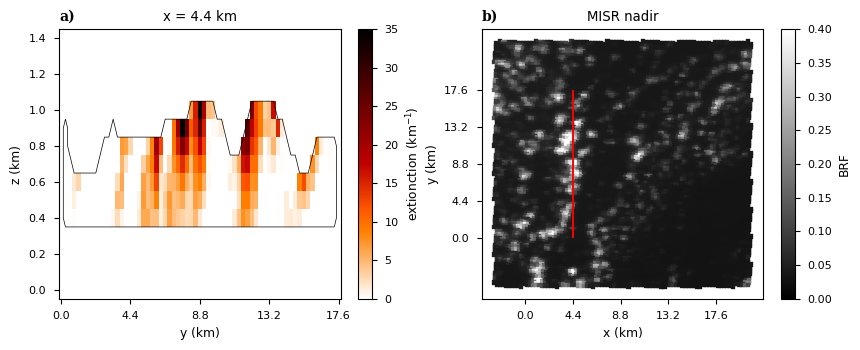

In [5]:
ext_cmap = 'gist_heat_r'
x = 4.4
vmax = 35
ticks = [0.0, 4.4, 8.8, 13.2, 17.6]
plt.style.use('seaborn-v0_8-paper')
f, ax = plt.subplots(1, 2, figsize=(10, 3.5))
cloud.sel(x=x, method='nearest').extinction.plot(
    y='z',
    ax=ax[0],
    vmin=0,
    vmax=vmax,
    cmap=ext_cmap,
    cbar_kwargs={'label': r'extionction (km$^{-1}$)'}
)
cvm.sel(x=x, method='nearest').cloud_volume_mask.plot.contour(
    y='z',
    levels=1, 
    ax=ax[0],
    colors='black',
    linewidths=0.5
)
ax[0].set_xlabel('y (km)')
ax[0].set_ylabel('z (km)')
ax[0].set_title('x = 4.4 km')
c = ax[1].scatter(
    obs['MISR']['sensor_list'][4].cam_x.data,
    obs['MISR']['sensor_list'][4].cam_y.data,
    c = (np.pi * obs['MISR']['sensor_list'][4].I.data) / obs['MISR']['sensor_list'][4].mu0,
    s = 10,
    cmap = 'gray',
    vmin = 0,
    vmax = 0.4,
    marker = 's'
)
plt.colorbar(c, ax=ax[1], label='BRF')
ax[1].vlines(x, 0, 17.6, colors='red')
ax[1].set_xlabel('x (km)')
ax[1].set_ylabel('y (km)')
ax[1].set_title('MISR nadir')
ax[0].set_xticks(ticks)
ax[1].set_xticks(ticks)
ax[1].set_yticks(ticks)

set_labels(ax.flatten())

if(savefigs):
    plt.savefig(
        FIGURE_OUT / '{}_figure09_extinction_transect.png'.format(fig_version),
        format='png',
        dpi=300,
        bbox_inches='tight',
        transparent=False
    )

### Figure 10: BRF

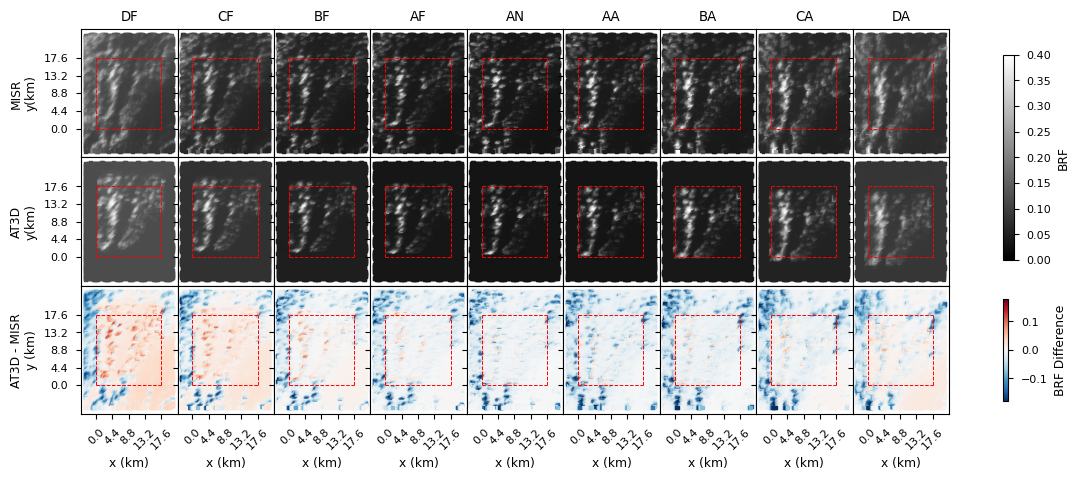

In [6]:
vmin = 0
vmax = 0.4
vrange = 0.18
s = 8
ticks = [0.0, 4.4, 8.8, 13.2, 17.6]

misr_obs = obs['MISR']['sensor_list']
at3d_obs = sensors['MISR']['sensor_list']

plt.style.use('seaborn-v0_8-paper')
f, ax = plt.subplots(3, 9, figsize=(14, 5), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.0, hspace=0.0)

for i, (mo, ao) in enumerate(zip(misr_obs, at3d_obs)):
    ax[0, i].scatter(
        mo.cam_x.data,
        mo.cam_y.data,
        c = (np.pi * mo.I.data) / mo.mu0,
        s = s,
        cmap = 'gray',
        vmin = vmin,
        vmax = vmax,
        marker = 's'
    )
    c1 = ax[1, i].scatter(
        ao.cam_x.data,
        ao.cam_y.data,
        c = (np.pi * ao.I.data) / ao.mu0,
        s = s,
        cmap = 'gray',
        vmin = vmin,
        vmax = vmax,
        marker = 's'
    )
    c2 = ax[2, i].scatter(
        ao.cam_x.data,
        ao.cam_y.data,
        c = ((np.pi * ao.I.data) / ao.mu0) - ((np.pi * mo.I.data) / mo.mu0),
        s = s,
        cmap = 'RdBu_r',
        vmin = -vrange,
        vmax = vrange,
        marker = 's'
    )
    ax[0,i].set_title(mo.name)
    ax[2,i].set_xlabel('x (km)')
plt.colorbar(c1, ax=ax[0:2, :], label='BRF', shrink=0.8)
plt.colorbar(c2, ax=ax[2,:], label='BRF Difference', shrink=0.8)
ax[0, 0].set_ylabel('MISR\ny(km)')
ax[1, 0].set_ylabel('AT3D\ny(km)')
ax[2, 0].set_ylabel('AT3D - MISR\ny (km)')

ls = '--'
lw = 0.7
for a in ax.flat:
    a.plot([0, 0], [0, 17.6], c='r', ls=ls, lw=lw)
    a.plot([0, 17.6], [0, 0], c='r', ls=ls, lw=lw)
    a.plot([17.6, 17.6], [0, 17.6], c='r', ls=ls, lw=lw)
    a.plot([0, 17.6], [17.6, 17.6], c='r', ls=ls, lw=lw)
    a.set_xticks(ticks)
    a.set_xticklabels(ticks, rotation=45)
    a.set_yticks(ticks)
# plt.xticks(rotation=45)
if(savefigs):
    plt.savefig(
        FIGURE_OUT / '{}_figure10_brf.png'.format(fig_version),
        format='png',
        dpi=300,
        bbox_inches='tight',
        transparent=False
    )

### Figure 12: Optical Depth

In [7]:
def interp_sensor_to_rte_grid(sensor, rte_grid, interp_var_name):
    x_sensor = sensor.ray_x.data
    y_sensor = sensor.ray_y.data
    interp_var = sensor[interp_var_name].data

    x_interp_to = rte_grid.x.data
    y_interp_to = rte_grid.y.data

    grid_x, grid_y = np.meshgrid(x_interp_to, y_interp_to, indexing='ij')
    var_interpolated = griddata((x_sensor, y_sensor), interp_var, (grid_x, grid_y), method='linear')
    rte_grid[interp_var_name] = (['x', 'y'], var_interpolated)
    return rte_grid

Cloud mask: cloud_mask_at3d
1D is 1.50% lower than AT3D


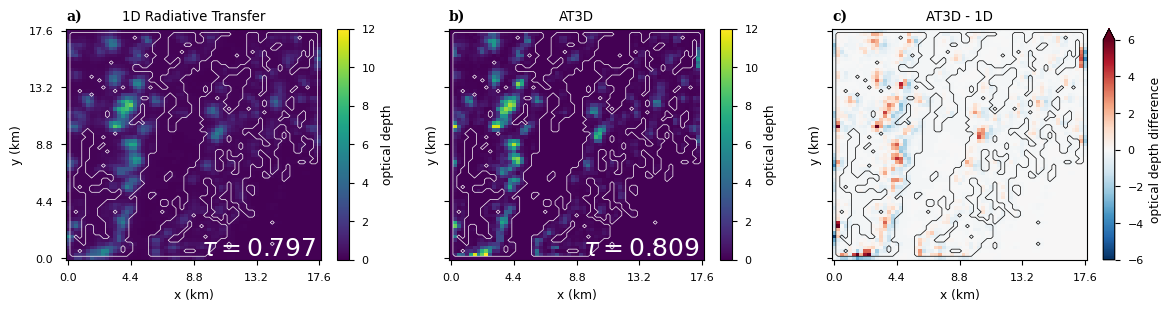

In [9]:
cloud['tau'] = cloud.extinction.integrate('z')

# tau1D_file = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/AT3D_1DTAU_CAMP2Ex_RF17_default_1400.nc'
tau1D_file = INTERIM_DATA / 'AT3D_1DTAU_CAMP2Ex_RF17_default.nc'
obs = load_sensor_dict(tau1D_file)
tau_1D_sensor = obs['MISR']['sensor_list'][4]

cloud_1D = rte_grid.copy(deep=True)
cloud_1D.attrs = tau_1D_sensor.attrs
cloud_1D = interp_sensor_to_rte_grid(tau_1D_sensor, cloud_1D, 'tau')
cloud_1D = interp_sensor_to_rte_grid(tau_1D_sensor, cloud_1D, 'I')

cvm['cloud_mask_cvm'] = (cvm.cloud_volume_mask.integrate('z') > 0).astype(int)
cvm['cloud_mask_at3d'] = (cloud.tau > 0).astype(int)
th_mask = (((np.pi * cloud_1D.I) / cloud_1D.mu0) > 0.04).astype(int).data
th_mask[0,:] = th_mask[-1,:] = th_mask[:,0] = th_mask[:,-1] = 0
cvm['cloud_mask_th'] = (['x', 'y'], th_mask)

vmin = 0
vmax = 12
vrange = 6
# cloud_mask_name = 'cloud_mask_cvm'
cloud_mask_name = 'cloud_mask_at3d'
# cloud_mask_name = 'cloud_mask_th'

plt.style.use('seaborn-v0_8-paper')
f, ax = plt.subplots(1, 3, figsize=(14, 3), sharex=True, sharey=True)
cloud_1D.tau.plot(
    ax=ax[0],
    y='y',
    vmin=vmin,
    vmax=vmax,
    cbar_kwargs={'label': 'optical depth'}
)
cloud.tau.plot(
    ax=ax[1],
    y='y',
    vmin=vmin,
    vmax=vmax,
    cbar_kwargs={'label': 'optical depth'}
)
(cloud.tau - cloud_1D.tau).plot(
    ax=ax[2],
    y='y',
    vmin=-vrange,
    vmax=vrange,
    cbar_kwargs={'label': 'optical depth difference'},
    cmap='RdBu_r'
)
cm_colors = ['white', 'white', 'black']
ticks = [0.0, 4.4, 8.8, 13.2, 17.6]
for i in range(len(ax)):
    cvm[cloud_mask_name].plot.contour(
        y='y',
        levels=1,
        ax=ax[i],
        colors=cm_colors[i],
        linewidths=0.5
    )
    ax[i].set_xlabel('x (km)')
    ax[i].set_ylabel('y (km)')
    ax[i].set_xticks(ticks)
    ax[i].set_yticks(ticks)
ax[0].set_title('1D Radiative Transfer')
ax[1].set_title('AT3D')
ax[2].set_title('AT3D - 1D')

tau_bar_1d = cloud_1D.tau.where(cvm[cloud_mask_name] > 0).mean().data
tau_bar_3d = cloud.tau.where(cvm[cloud_mask_name] > 0).mean().data

ax[0].text(17.4, 0.2, r'$\tau = {:.3f}$'.format(tau_bar_1d), ha='right', c='white', size=18)
ax[1].text(17.4, 0.2, r'$\tau = {:.3f}$'.format(tau_bar_3d), ha='right', c='white', size=18)

print('Cloud mask: {}'.format(cloud_mask_name))
print('1D is {:.2f}% lower than AT3D'.format(100*(tau_bar_3d - tau_bar_1d) / tau_bar_3d))

set_labels(ax.flatten())

if(savefigs):
    plt.savefig(
        FIGURE_OUT / '{}_figure12_optical_depth_{}.png'.format(fig_version, cloud_mask_name),
        format='png',
        dpi=300,
        bbox_inches='tight',
        transparent=False
    )
